# EGLL – локальная доступность траекторий

**Этап 01 · 12 октября 2026**

Вопрос: содержат ли сохраненные локальные источники последовательные наблюдения, из которых можно построить пилот конечного захода EGLL?

Область аудита: исходная европейская таблица версии 1.0 и 11 CSV из прежнего манифеста траекторий. Проверяются фактическая схема, контрольные суммы и наличие координат в широком поисковом прямоугольнике вокруг EGLL. Это ограниченная инвентаризация, не полный поиск всех возможных источников и не разметка заходов.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

# Находим внешний исторический источник через общий реестр
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
PROJECT = BASE.parents[1]
config = json.loads((PROJECT / 'configs/sources.json').read_text(encoding='utf-8'))
OLD = (PROJECT / config['airport_summary']).resolve().parents[2]
for name in ['reports', 'figures']:
    (BASE / name).mkdir(exist_ok=True)
RED, GREEN = '#D65A4A', '#00897B'
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
manifest_path = OLD / 'research/final-approach-dynamics/reports/00_inventory_manifest.json'
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))

# Читаем только метаданные Parquet без загрузки миллионов строк
parquet_path = OLD / 'europe/data/source/osn23_landings_merged.parquet.gzip'
with pq.ParquetFile(parquet_path) as parquet:
    schema = pd.DataFrame([{'field': field.name, 'type': str(field.type)}
                           for field in parquet.schema_arrow])
    parquet_rows = parquet.metadata.num_rows
schema.to_csv(BASE / 'reports/01_source_schema.csv', index=False)
print('Строк в исходном Parquet:', parquet_rows)
display(schema)

,field,type
0,flight_id,string
1,callsign,string
2,icao24,string
3,landing_time,"timestamp[ns, tz=UTC]"
4,registration,string
5,typecode,string
6,icaoaircrafttype,string
7,airport,string
8,country,string
9,attempt_times,"list<element: timestamp[us, tz=UTC]>"


Строк в исходном Parquet: 7984254


## Проверка сохраненных временных рядов

Поисковый прямоугольник **51,2–51,8° N; 0,9–0,1° W** намеренно широк. Координаты в нем означают только пространственных кандидатов, включая возможные пролеты и соседние аэропорты. Нулевое число кандидатов относится только к проверенным файлам. Порог не используется для определения ВПП, захвата ILS или события GoA.

Контрольная сумма каждого CSV сравнивается с прежним манифестом. Метки GoA не выводятся из самого факта наличия траектории.

In [2]:
rows = []
fields = []
fragments = []
for item in manifest['sources']:
    path = OLD / item['source']
    if not path.is_file():
        rows.append({'source': item['source'], 'status': 'Файл отсутствует'})
        continue
    # Проверяем происхождение до анализа содержимого
    with path.open('rb') as stream:
        digest = hashlib.file_digest(stream, 'sha256').hexdigest()
    frame = pd.read_csv(path, dtype={'icao24': str})
    # Считаем пространственных кандидатов без присвоения аэропорта
    candidate = frame['lat'].between(51.2, 51.8) & frame['lon'].between(-0.9, -0.1)
    # Группируем кандидатов по файлу и борту без присвоения попытки захода
    for aircraft, group in frame.loc[candidate].groupby('icao24'):
        ordered = group.sort_values('time')
        gaps = ordered.time.diff()
        fragments.append({'source': item['source'], 'icao24': aircraft,
                          'rows': len(group),
                          'utc_start': str(pd.to_datetime(group.time.min(), unit='s', utc=True)),
                          'utc_end': str(pd.to_datetime(group.time.max(), unit='s', utc=True)),
                          'span_s': group.time.max() - group.time.min(),
                          'max_gap_s': gaps.max(),
                          'baroaltitude_min_raw': group.baroaltitude.min(),
                          'baroaltitude_max_raw': group.baroaltitude.max(),
                          'geoaltitude_min_raw': group.geoaltitude.min(),
                          'geoaltitude_max_raw': group.geoaltitude.max()})
    label_fields = [name for name in frame.columns
                    if name.lower() in {'goa', 'has_ga', 'go_around', 'go_arounds'}]
    rows.append({'source': item['source'], 'status': 'Проверен',
                 'sha256': digest, 'matches_manifest': digest == item['sha256'],
                 'rows': len(frame), 'candidate_rows': int(candidate.sum()),
                 'candidate_aircraft': frame.loc[candidate, 'icao24'].nunique(),
                 'label_fields': ', '.join(label_fields) or 'Отсутствуют'})
    for name in frame.columns:
        fields.append({'source': item['source'], 'field': name,
                       'nonmissing_rows': int(frame[name].notna().sum())})
inventory = pd.DataFrame(rows)
inventory.to_csv(BASE / 'reports/01_local_trajectory_inventory.csv', index=False)
pd.DataFrame(fields).to_csv(BASE / 'reports/01_trajectory_fields.csv', index=False)
display(inventory[['source', 'status', 'matches_manifest', 'rows',
                   'candidate_rows', 'candidate_aircraft', 'label_fields']])
assert inventory['status'].eq('Проверен').all(), 'Инвентаризация неполна'
assert inventory['matches_manifest'].all(), 'Исходники изменились относительно манифеста'
print('Проверено файлов:', len(inventory))
print('Строк в поисковом прямоугольнике:', int(inventory.candidate_rows.sum()))

,source,status,matches_manifest,rows,candidate_rows,candidate_aircraft,label_fields
0,research/c40_geometry/data/expanded_training/2...,Проверен,True,1811,23,1,Отсутствуют
1,research/c40_geometry/data/expanded_training/2...,Проверен,True,1790,0,0,Отсутствуют
2,research/c40_geometry/data/expanded_training/2...,Проверен,True,3040,38,2,Отсутствуют
3,research/c40_geometry/data/expanded_training/2...,Проверен,True,1903,60,2,Отсутствуют
4,research/c40_geometry/data/expanded_training/2...,Проверен,True,2474,36,1,Отсутствуют
5,research/c40_geometry/data/external_day/state_...,Проверен,True,2236,14,2,Отсутствуют
6,research/c40_geometry/data/hermite_validation/...,Проверен,True,1761,0,0,Отсутствуют
7,research/c40_geometry/data/hermite_validation/...,Проверен,True,2240,5,1,Отсутствуют
8,research/c40_geometry/data/public_pilot/ENT73J...,Проверен,True,359,0,0,Отсутствуют
9,research/c40_geometry/data/public_pilot/ENT73J...,Проверен,True,130,0,0,Отсутствуют


Проверено файлов: 11
Строк в поисковом прямоугольнике: 239


## Характер пространственных фрагментов

Группы ниже определены по файлу и ICAO24. Это не выделенные попытки захода: временной размах может включать разрывы, а файлы могут перекрываться. Высоты показаны в исходных значениях; система отсчета и единицы должны быть подтверждены по источнику до применения границы 300 ft.

In [3]:
# Сохраняем диапазоны времени и высоты без исправления исходных значений
fragment_table = pd.DataFrame(fragments)
fragment_table.to_csv(BASE / 'reports/01_candidate_fragments.csv', index=False)
display(fragment_table)
print('Групп файл / ICAO24:', len(fragment_table))
print('Уникальных ICAO24:', fragment_table.icao24.nunique())

,source,icao24,rows,utc_start,utc_end,span_s,max_gap_s,baroaltitude_min_raw,baroaltitude_max_raw,geoaltitude_min_raw,geoaltitude_max_raw
0,research/c40_geometry/data/expanded_training/2...,40666b,23,2019-11-04 22:07:40+00:00,2019-11-04 22:11:20+00:00,220,10.0,10972.80,10980.42,10637.52,10652.76
1,research/c40_geometry/data/expanded_training/2...,4010ee,4,2019-11-18 22:07:00+00:00,2019-11-18 22:07:30+00:00,30,10.0,11582.40,11590.02,11483.34,11490.96
2,research/c40_geometry/data/expanded_training/2...,406016,34,2019-11-18 22:09:00+00:00,2019-11-18 22:14:30+00:00,330,10.0,10972.80,10980.42,10911.84,10919.46
3,research/c40_geometry/data/expanded_training/2...,4074b7,30,2019-11-25 22:07:50+00:00,2019-11-25 22:12:40+00:00,290,10.0,11574.78,11590.02,11605.26,11628.12
4,research/c40_geometry/data/expanded_training/2...,4ca891,30,2019-11-25 22:06:00+00:00,2019-11-25 22:10:50+00:00,290,10.0,11582.40,11590.02,11597.64,11620.50
5,research/c40_geometry/data/expanded_training/2...,4ca75f,36,2019-12-02 22:18:40+00:00,2019-12-02 22:24:30+00:00,350,10.0,10668.00,10668.00,10904.22,10911.84
6,research/c40_geometry/data/external_day/state_...,3c65d4,1,2019-10-28 22:05:50+00:00,2019-10-28 22:05:50+00:00,0,NaN,11292.84,11292.84,11391.90,11391.90
7,research/c40_geometry/data/external_day/state_...,406909,13,2019-10-28 22:00:10+00:00,2019-10-28 22:02:10+00:00,120,10.0,10972.80,10988.04,11079.48,11109.96
8,research/c40_geometry/data/hermite_validation/...,406012,5,2019-12-16 22:29:50+00:00,2019-12-16 22:30:30+00:00,40,10.0,10965.18,10972.80,10721.34,10728.96
9,research/c40_geometry/data/public_pilot/EPWA_c...,406668,1,2019-10-21 22:31:20+00:00,2019-10-21 22:31:20+00:00,0,NaN,10972.80,10972.80,11087.10,11087.10


Групп файл / ICAO24: 12
Уникальных ICAO24: 12


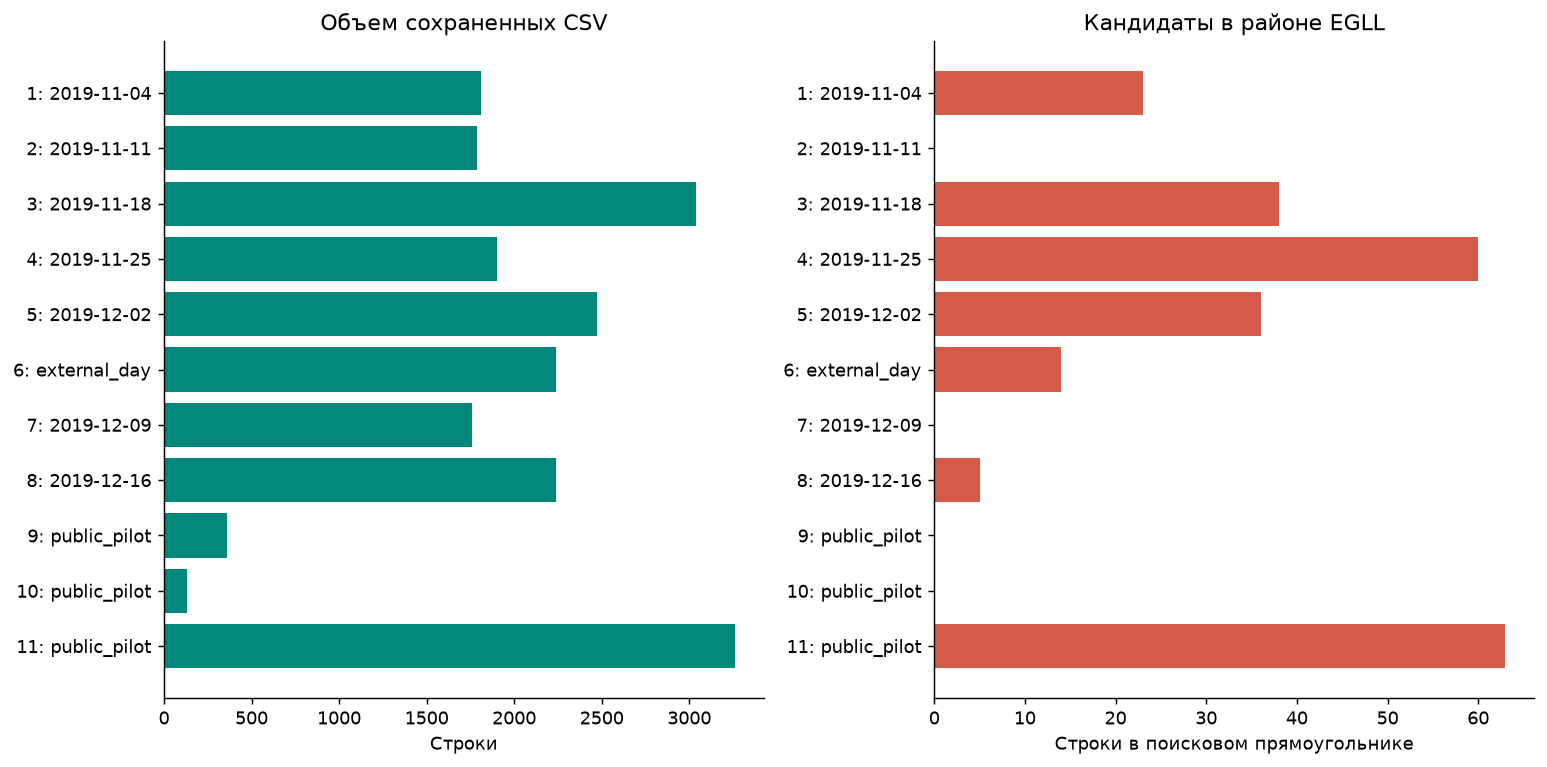

In [4]:
# Сравниваем объем файлов с пространственными кандидатами
labels = [str(i + 1) + ': ' + Path(p).parent.name for i, p in enumerate(inventory.source)]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].barh(labels, inventory.rows, color=GREEN)
axes[0].set(title='Объем сохраненных CSV', xlabel='Строки')
axes[1].barh(labels, inventory.candidate_rows, color=RED)
axes[1].set(title='Кандидаты в районе EGLL', xlabel='Строки в поисковом прямоугольнике')
if inventory.candidate_rows.sum() == 0:
    axes[1].set_xlim(0, 1)
    axes[1].text(0.5, 0.5, 'Кандидаты отсутствуют', ha='center', transform=axes[1].transAxes)
for ax in axes:
    ax.invert_yaxis()
fig.tight_layout()
for ext in ['png', 'svg']:
    fig.savefig(BASE / f'figures/01_local_inventory.{ext}', bbox_inches='tight')
plt.show()

## Интерпретация и следующий шаг

Проверены 11 файлов; все контрольные суммы совпали с прежним манифестом. В поисковой области EGLL найдены 239 строк в 7 файлах. Поля меток GoA в этих CSV отсутствуют. Пространственное совпадение само по себе не подтверждает конечный заход в аэропорт.

Кандидаты образуют 12 групп файл / ICAO24. Размах времени каждой группы – от 0 до 350 секунд, минимальное исходное значение барометрической высоты – 10668. В принятой для OpenSky системе единиц это 10,668 км, что указывает на высотные пролеты, а не конечный участок. Единицы высоты в метрах описаны в [официальной документации OpenSky](https://openskynetwork.github.io/opensky-api/rest.html); локальный скрипт прежнего проекта analyze_public_pilot.py также обозначает baroaltitude как метры. Это не высота над аэродромом.

Основной Parquet содержит flight_id, icao24, landing_time, attempt_times, ILS, n_attempts, GoA и метаданные C40. Его схема не содержит последовательного ряда координат, высоты, скорости и вертикальной скорости. Аэропортовые записи с метаданными C40 нельзя автоматически считать полными конечными траекториями.

Необходимо сопоставить результат пространственной проверки с наличием меток и покрытием конечного участка. До появления подходящих рядов нельзя обоснованно выбрать направление ВПП и проверить мониторинг до 300 ft.

В проверенном наборе пригодные ряды конечного захода EGLL не найдены. Этот вывод не распространяется на другие локальные файлы или внешние архивы.

Для следующего этапа требуется реестр источников с условиями доступа, датами, полями и возможностью связать наблюдения с попыткой захода. Массовая загрузка не входит в текущую инвентаризацию. Тема возможного доклада формируется после первого подтвержденного результата о качестве данных или поведении baseline.